# Machine Learning – Practical Session 4
## Overfitting, data leakage and model generalization


In [4]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
CSV_PATH = "hybrid_student_performance_1200.csv"

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")


In [5]:
df_raw = pd.read_csv(CSV_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print(df_raw.dtypes)


Shape: (1200, 36)


,student_id,timestamp,year_class,program_stream,age,gender,cgpa_category,academic_satisfaction,study_hours_daily,daily_productivity,revision_frequency,focus_duration,screen_time_non_study,main_distractor,study_consistency,tasks_on_time,preparation_status,career_goal_clarity,skills_developing,energy_level,stress_level,routine_rating,sleepy_during_study,sleep_hours,career_interest,online_courses,projects_internships,programming_foundation,events_participation,assignments_on_time,attendance_percentage,strongest_asset,internal_barrier,external_resources,external_pressure,performance_risk_level
0,STU0001,3/29/2026 20:54:43,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,Less than 1 hour,2.0,Never,1–2 hours,More than 6 hours,Social media,Rarely,Sometimes,Planning to start soon,Somewhat clear,"Hard skills (programming, data analytics, tech...",4.0,4.0,1.0,Sometimes,6–7 hours,Other,"Not currently, but intend to in the future","Yes, actively working on projects/internship","Basic knowledge, learning while practicing",Occasionally participate in events,Often,Above 85%,"Technical/Hard Skills (Coding, Math, Logic)",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),No Impact (Fully supportive environment),Moderate Risk
1,STU0002,3/29/2026 21:20:15,Second Year (SY),BCA,20,Male,8.5 – 9.4,Unsatisfied,1–2 hours,1.0,Rarely,30–60 minutes,2–4 hours,Video content (YouTube/OTT),Sometimes,Sometimes,Planning to start soon,Somewhat clear,Both hard and soft skills,2.0,3.0,1.0,Often,6–7 hours,Automation Engineer,"Yes, currently enrolled in one or more courses...","Yes, actively working on projects/internship","Limited knowledge, theoretical only","Rarely participate, mostly observe",Often,76% – 85%,"Creative/Design Skills (Innovation, UI/UX, Con...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),Moderate Impact (Occasional disruption),Moderate Risk
2,STU0003,3/29/2026 21:21:35,Second Year (SY),BCA,19,Male,5.0 – 6.9,Neutral,1–2 hours,2.0,Few times a week,1–2 hours,4–6 hours,Social interactions,Mostly consistent,Often,Actively preparing for a goal (placements/exams),Very clear,Both hard and soft skills,4.0,5.0,2.0,Often,6–7 hours,Cyber Security Analyst,Planning to enroll soon,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Less than 50%,"Technical/Hard Skills (Coding, Math, Logic)",Difficulty with Focus / Concentration,Rarely (Passive),High Impact (Frequent disruption),High Risk
3,STU0004,3/29/2026 21:27:44,Second Year (SY),BCA,19,Female,8.5 – 9.4,Satisfied,1–2 hours,3.0,Rarely,1–2 hours,More than 6 hours,Social interactions,Sometimes,Often,Planning to start soon,Somewhat clear,Both hard and soft skills,3.0,2.0,2.0,Always,6–7 hours,Cyber Security Analyst,Planning to enroll soon,Planning to start a project/internship soon,"Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Above 85%,"Management/Execution (Planning, Organizing, Di...",Procrastination / Low Motivation,Occasionally (When needed),High Impact (Frequent disruption),Low Risk
4,STU0005,3/29/2026 22:05:14,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,1–2 hours,2.0,Rarely,1–2 hours,4–6 hours,Social media,Sometimes,Sometimes,Planning to start soon,Somewhat clear,Both hard and soft skills,3.0,5.0,2.0,Always,4–5 hours,Data Analyst,Planning to enroll soon,Planning to start a project/internship soon,"Basic knowledge, learning while practicing",Occasionally participate in events,Often,76% – 85%,"Management/Execution (Planning, Organizing, Di...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),High Impact (Frequent disruption),High Risk


student_id                    str
timestamp                     str
year_class                    str
program_stream                str
age                         int64
gender                        str
cgpa_category                 str
academic_satisfaction         str
study_hours_daily             str
daily_productivity        float64
revision_frequency            str
focus_duration                str
screen_time_non_study         str
main_distractor               str
study_consistency             str
tasks_on_time                 str
preparation_status            str
career_goal_clarity           str
skills_developing             str
energy_level              float64
stress_level              float64
routine_rating            float64
sleepy_during_study           str
sleep_hours                   str
career_interest               str
online_courses                str
projects_internships          str
programming_foundation        str
events_participation          str
assignments_on

In [6]:

required = [
    "student_id", "timestamp", "cgpa_category", "performance_risk_level",
    "study_hours_daily", "sleep_hours", "attendance_percentage",
    "study_consistency", "tasks_on_time", "assignments_on_time",
    "revision_frequency", "career_goal_clarity", "daily_productivity",
    "stress_level", "age", "program_stream", "year_class"
]
missing_cols = [c for c in required if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Missing expected columns in CSV: {missing_cols}")

df = df_raw.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")


## Part A – Data inspection and potential leakage

In [7]:
print("Dimensions:", df.shape)
display(df.describe(include="all").T)
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": 100 * df.isna().mean()
}).sort_values("missing_percent", ascending=False)
display(missing_summary[missing_summary.missing_count > 0])

# Duplicates: exact rows, excluding student_id, and ignoring timestamp
dup_exact = int(df.duplicated().sum())
dup_without_id = int(df.drop(columns=["student_id"]).duplicated().sum())
dup_ignoring_timestamp = int(df.drop(columns=["timestamp"]).duplicated().sum())
print("Exact duplicate rows:", dup_exact)
print("Duplicates excluding student_id:", dup_without_id)
print("Duplicates ignoring timestamp:", dup_ignoring_timestamp)


Dimensions: (1200, 36)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
student_id,1200,1200,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,1200,NaN,NaN,NaN,2026-03-30 07:20:15.285000,2026-03-15 01:07:00,2026-03-22 10:58:30,2026-03-30 09:05:00,2026-04-06 23:02:00,2026-04-14 22:27:00,NaN
year_class,1200,6,Second Year (SY),365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
program_stream,1200,7,BCA,696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1200.0,NaN,NaN,NaN,20.8075,17.0,19.0,21.0,22.0,26.0,2.186953
gender,1200,3,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cgpa_category,1200,4,7.0 – 8.4,420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
academic_satisfaction,1200,5,Neutral,426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
study_hours_daily,1200,3,1–2 hours,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
daily_productivity,1166.0,NaN,NaN,NaN,2.686964,1.0,2.0,3.0,3.0,5.0,1.178761


,missing_count,missing_percent
events_participation,58,4.833333
sleep_hours,55,4.583333
external_resources,45,3.750000
focus_duration,43,3.583333
routine_rating,41,3.416667
programming_foundation,41,3.416667
online_courses,36,3.000000
stress_level,35,2.916667
revision_frequency,34,2.833333
daily_productivity,34,2.833333


Exact duplicate rows: 0
Duplicates excluding student_id: 0
Duplicates ignoring timestamp: 0


In [8]:
# Encode target and numeric/ordinal predictors
cgpa_map = {
    "5.0–6.9": 5.95, "5.0-6.9": 5.95,
    "7.0–8.4": 7.70, "7.0-8.4": 7.70,
    "8.5–9.4": 8.95, "8.5-9.4": 8.95,
    "9.5–10.0": 9.75, "9.5-10.0": 9.75
}
def normalize_text(x):
    if pd.isna(x): return np.nan
    return str(x).strip()

df["cgpa_category"] = df["cgpa_category"].map(normalize_text)
# Also tolerate alternative hyphen/dash formatting and spaces
def cgpa_midpoint(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().replace(" ", "").replace("–", "-").replace("—", "-")
    mapping = {"5.0-6.9":5.95, "7.0-8.4":7.70, "8.5-9.4":8.95, "9.5-10.0":9.75}
    return mapping.get(s, np.nan)

df["final_cgpa"] = df["cgpa_category"].apply(cgpa_midpoint)

encodings = {
    "study_hours_daily": {
        "Less than 1 hour": 0.5, "1–2 hours": 1.5, "1-2 hours": 1.5,
        "More than 2 hours": 2.5
    },
    "sleep_hours": {
        "4–5 hours": 4.5, "4-5 hours": 4.5, "6–7 hours": 6.5,
        "6-7 hours": 6.5, "More than 8 hours": 8.5
    },
    "attendance_percentage": {
        "Less than 50%": 40, "50–65%": 57.5, "50-65%": 57.5,
        "66–75%": 70.5, "66-75%": 70.5, "76–85%": 80.5,
        "76-85%": 80.5, "Above 85%": 92.5
    },
    "study_consistency": {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2},
    "tasks_on_time": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3},
    "assignments_on_time": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3},
    "revision_frequency": {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3},
    "career_goal_clarity": {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2}
}
for col, mapping in encodings.items():
    df[col] = df[col].map(lambda x: mapping.get(normalize_text(x), np.nan))

rename = {"study_hours_daily": "study_hours", "attendance_percentage": "attendance_rate"}
df = df.rename(columns=rename)

# Submission day: elapsed days since first valid submission
first_time = df["timestamp"].min()
df["submission_day"] = (df["timestamp"] - first_time).dt.total_seconds() / 86400

# cohort_code: combined categorical identifier
df["cohort_code"] = (
    df["program_stream"].fillna("Missing").astype(str).str.strip()
    + " | " +
    df["year_class"].fillna("Missing").astype(str).str.strip()
)

# effort_index: row-wise mean; fixed divisors, no learned statistic
effort_components = pd.DataFrame({
    "study_hours_scaled": df["study_hours"] / 2.5,
    "attendance_scaled": df["attendance_rate"] / 100,
    "consistency_scaled": df["study_consistency"] / 2,
    "tasks_scaled": df["tasks_on_time"] / 3,
    "assignments_scaled": df["assignments_on_time"] / 3,
    "revision_scaled": df["revision_frequency"] / 3
}, index=df.index)
df["effort_index"] = effort_components.mean(axis=1, skipna=True)

print("Rows without a usable target:", df["final_cgpa"].isna().sum())
display(df[["cgpa_category", "final_cgpa"]].drop_duplicates().sort_values("final_cgpa"))


Rows without a usable target: 0


,cgpa_category,final_cgpa
2,5.0 – 6.9,5.95
6,7.0 – 8.4,7.70
0,8.5 – 9.4,8.95
5,9.5 – 10.0,9.75


,correlation_with_final_cgpa
age,-0.024322
sleep_hours,-0.010040
stress_level,0.019408
submission_day,0.020354
revision_frequency,0.071053
assignments_on_time,0.075506
tasks_on_time,0.097202
career_goal_clarity,0.120848
daily_productivity,0.132224
study_hours,0.296876


Strongest: attendance_rate = 0.5245683914949574
Weakest: sleep_hours = -0.010039756795691126


cgpa_category,5.0 – 6.9,7.0 – 8.4,8.5 – 9.4,9.5 – 10.0,All
performance_risk_level,,,,,
High Risk,188,221,39,4,452
Low Risk,0,4,89,83,176
Moderate Risk,48,195,234,95,572
All,236,420,362,182,1200


Number of cohort categories: 42
Categories with fewer than 10 rows: 12


cohort_code
BBA | Second Year (PG)                   3
BA | Final Year                          3
BSc Cyber Security | Final Year          4
BSc IT | Second Year (PG)                5
BBA | Final Year                         6
BA | Second Year (PG)                    6
BBA | First Year (PG)                    6
BCom | Final Year                        6
BSc Cyber Security | Second Year (PG)    7
BA | First Year (FY)                     7
BA | First Year (PG)                     8
BCom | Second Year (PG)                  9
Name: count, dtype: int64

Already chronological: False


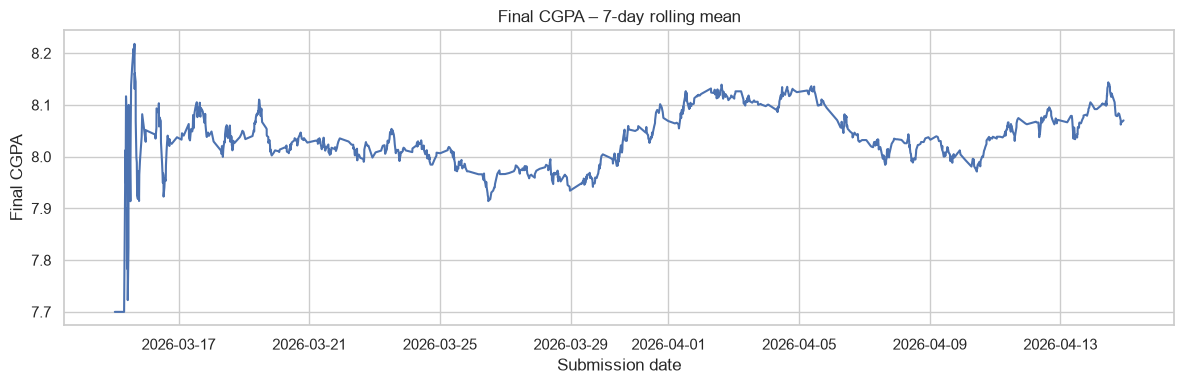

In [9]:
# Correlation of numeric features with target
numeric_for_corr = [
    "study_hours", "sleep_hours", "attendance_rate", "study_consistency",
    "tasks_on_time", "assignments_on_time", "revision_frequency",
    "career_goal_clarity", "daily_productivity", "stress_level", "age",
    "submission_day", "effort_index", "final_cgpa"
]
corr = df[numeric_for_corr].corr(numeric_only=True)["final_cgpa"].drop("final_cgpa").sort_values()
display(corr.to_frame("correlation_with_final_cgpa"))
print("Strongest:", corr.abs().idxmax(), "=", corr.loc[corr.abs().idxmax()])
print("Weakest:", corr.abs().idxmin(), "=", corr.loc[corr.abs().idxmin()])

# Risk label vs target category
display(pd.crosstab(df["performance_risk_level"], df["cgpa_category"], margins=True))

cohort_counts = df["cohort_code"].value_counts()
print("Number of cohort categories:", cohort_counts.size)
print("Categories with fewer than 10 rows:", int((cohort_counts < 10).sum()))
display(cohort_counts[cohort_counts < 10].sort_values())

already_sorted = df["timestamp"].is_monotonic_increasing
print("Already chronological:", already_sorted)
df = df.sort_values("timestamp").reset_index(drop=True)
daily = df.set_index("timestamp")["final_cgpa"].rolling("7D", min_periods=1).mean()
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values)
plt.title("Final CGPA – 7-day rolling mean")
plt.xlabel("Submission date"); plt.ylabel("Final CGPA"); plt.tight_layout(); plt.show()


### Part A – Risks to Discuss

- **Repeated submissions:** If the same student's answers appear in both the training and test sets, the model may learn from information that is also present during testing. This can lead to overly optimistic evaluation results.

- **Preprocessing leakage:** If preprocessing steps, such as missing-value imputation or feature scaling, are fitted on the entire dataset before splitting, information from the test set can influence the training process. These steps should be fitted only on the training data.

- **Rare cohort categories:** Some cohort groups contain very few observations. The model may learn unstable patterns from these small groups, increasing the risk of overfitting.

- **Risk label leakage:** The `performance_risk_level` feature is closely related to academic performance and CGPA. Including it could reveal information about the target variable, so it must be excluded from the predictors.

## Common features and chronological split (used from Part B onward)

In [10]:
# Predictors listed in Part B; cohort_code is reserved for Part D.1
feature_cols = [
    "study_hours", "sleep_hours", "attendance_rate", "study_consistency",
    "tasks_on_time", "assignments_on_time", "revision_frequency",
    "career_goal_clarity", "daily_productivity", "stress_level", "age",
    "submission_day"
]
model_df = df.dropna(subset=["final_cgpa"]).copy()
X = model_df[feature_cols]
y = model_df["final_cgpa"]

split_idx = int(len(model_df) * 0.80)
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (960, 12) Test: (240, 12)


## Part B – Impact of data leakage and evaluation strategy

### B.1 Random split versus chronological split

In [11]:
tree = DecisionTreeRegressor(random_state=RANDOM_STATE)
# Random split comparison
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
random_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))])
random_model.fit(Xr_train, yr_train)
chrono_model = clone(random_model).fit(X_train, y_train)

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
b1_rows = [
    ["Random split", rmse(yr_train, random_model.predict(Xr_train)), rmse(yr_test, random_model.predict(Xr_test))],
    ["Chronological split", rmse(y_train, chrono_model.predict(X_train)), rmse(y_test, chrono_model.predict(X_test))],
    ["Baseline (train mean)", rmse(y_train, dummy.predict(X_train)), rmse(y_test, dummy.predict(X_test))]
]
b1_results = pd.DataFrame(b1_rows, columns=["Strategy", "Training RMSE", "Testing RMSE"])
display(b1_results)


,Strategy,Training RMSE,Testing RMSE
0,Random split,5.446509e-16,1.530567
1,Chronological split,4.134246e-16,2.067597
2,Baseline (train mean),1.268541e+00,1.236164


### B.2 Duplicate leakage

In [12]:
# Simulate 15% duplicated submissions; each copy gets a random timestamp in survey period.
aug_base = model_df.copy()
n_dup = int(round(0.15 * len(aug_base)))
sampled = aug_base.sample(n=n_dup, random_state=RANDOM_STATE).copy()
period_start, period_end = aug_base["timestamp"].min(), aug_base["timestamp"].max()
rng = np.random.default_rng(RANDOM_STATE)
span_seconds = max((period_end - period_start).total_seconds(), 1)
sampled["timestamp"] = period_start + pd.to_timedelta(
    rng.uniform(0, span_seconds, size=n_dup), unit="s"
)
aug = pd.concat([aug_base, sampled], ignore_index=True).sort_values("timestamp").reset_index(drop=True)
aug["submission_day"] = (aug["timestamp"] - aug["timestamp"].min()).dt.total_seconds()/86400

aug_X = aug[feature_cols]
aug_y = aug["final_cgpa"]
aug_split = int(0.80 * len(aug))
Xa_tr, Xa_te = aug_X.iloc[:aug_split], aug_X.iloc[aug_split:]
ya_tr, ya_te = aug_y.iloc[:aug_split], aug_y.iloc[aug_split:]
dup_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("tree", DecisionTreeRegressor(random_state=RANDOM_STATE))])
dup_model.fit(Xa_tr, ya_tr)

# Remove duplicate answer records BEFORE splitting, ignoring timestamp and student_id.
dedup = aug.drop_duplicates(subset=[c for c in aug.columns if c not in ["timestamp", "submission_day", "student_id"]])
dedup = dedup.sort_values("timestamp").reset_index(drop=True)
Xd, yd = dedup[feature_cols], dedup["final_cgpa"]
d_split = int(0.80 * len(dedup))
Xd_tr, Xd_te = Xd.iloc[:d_split], Xd.iloc[d_split:]
yd_tr, yd_te = yd.iloc[:d_split], yd.iloc[d_split:]
dedup_model = clone(dup_model).fit(Xd_tr, yd_tr)

b2_results = pd.DataFrame([
    ["Duplicates retained", rmse(ya_tr, dup_model.predict(Xa_tr)), rmse(ya_te, dup_model.predict(Xa_te))],
    ["Duplicates removed before split", rmse(yd_tr, dedup_model.predict(Xd_tr)), rmse(yd_te, dedup_model.predict(Xd_te))]
], columns=["Strategy", "Training RMSE", "Testing RMSE"])
display(b2_results)
print("Augmented rows:", len(aug), "| after deduplication:", len(dedup))


,Strategy,Training RMSE,Testing RMSE
0,Duplicates retained,6.655973e-16,1.548094
1,Duplicates removed before split,4.684036e-16,1.754616


Augmented rows: 1380 | after deduplication: 1200


### B.3 Preprocessing leakage with KNN

In [13]:
knn = KNeighborsRegressor(n_neighbors=10)

# Incorrect: scaler is fitted on the complete dataset before the split.
all_imputed = SimpleImputer(strategy="median").fit_transform(X)
scaler_all = StandardScaler().fit(all_imputed)
X_all_scaled = scaler_all.transform(all_imputed)
Xall_tr, Xall_te = X_all_scaled[:split_idx], X_all_scaled[split_idx:]
knn_all = KNeighborsRegressor(n_neighbors=10).fit(Xall_tr, y_train)
leaky_train_rmse = rmse(y_train, knn_all.predict(Xall_tr))
leaky_test_rmse = rmse(y_test, knn_all.predict(Xall_te))

# Correct: imputation and scaling are learned only from training data.
knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=10))
]).fit(X_train, y_train)
correct_train_rmse = rmse(y_train, knn_pipe.predict(X_train))
correct_test_rmse = rmse(y_test, knn_pipe.predict(X_test))

b3_results = pd.DataFrame([
    ["Scaler fitted on all data (leakage)", leaky_train_rmse, leaky_test_rmse],
    ["Pipeline fitted on training only", correct_train_rmse, correct_test_rmse]
], columns=["Strategy", "Training RMSE", "Testing RMSE"])
display(b3_results)


,Strategy,Training RMSE,Testing RMSE
0,Scaler fitted on all data (leakage),1.100140,1.185845
1,Pipeline fitted on training only,1.093132,1.190360


**Interpretation:** the first method uses test-period means and standard deviations when transforming the training data. The numerical difference may be small, but it is still leakage. The same rule applies to imputation medians: learn them from training data only, then apply the learned transformation to validation/test data.

## Part C – Understanding and diagnosing overfitting

### C.1 Effect of decision-tree complexity

,max_depth,Training RMSE,Testing RMSE,Generalization gap
0,1,1.223105e+00,1.174393,-0.048712
1,2,1.184931e+00,1.145821,-0.039110
2,3,1.155347e+00,1.134088,-0.021259
3,5,1.075974e+00,1.152296,0.076322
4,10,6.974508e-01,1.996669,1.299218
5,20,5.155987e-02,2.055929,2.004369
6,None,4.134246e-16,2.067597,2.067597


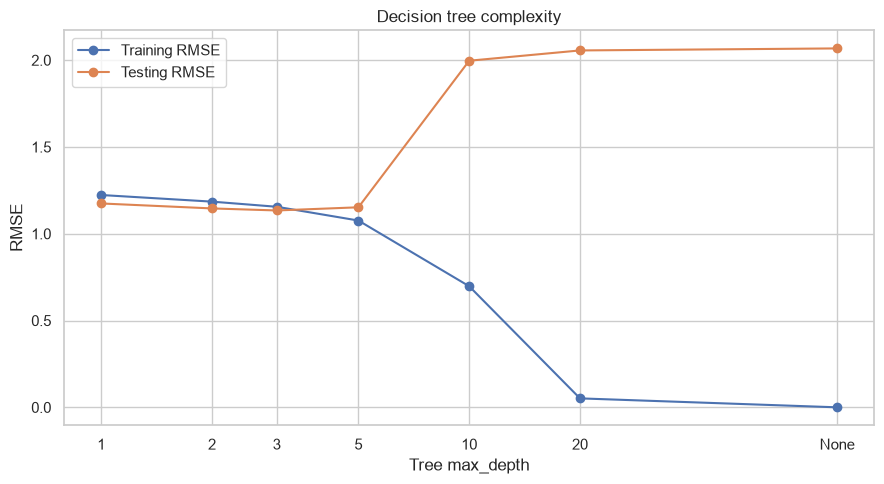

Lowest test RMSE depth: 3


In [14]:
depths = [1, 2, 3, 5, 10, 20, None]
depth_rows = []
for depth in depths:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train, y_train)
    depth_rows.append({
        "max_depth": "None" if depth is None else str(depth),
        "Training RMSE": rmse(y_train, pipe.predict(X_train)),
        "Testing RMSE": rmse(y_test, pipe.predict(X_test)),
        "Generalization gap": rmse(y_test, pipe.predict(X_test)) - rmse(y_train, pipe.predict(X_train))
    })
depth_results = pd.DataFrame(depth_rows)
display(depth_results)

plot_depth = [100 if d is None else d for d in depths]
plt.figure(figsize=(9, 5))
plt.plot(plot_depth, depth_results["Training RMSE"], marker="o", label="Training RMSE")
plt.plot(plot_depth, depth_results["Testing RMSE"], marker="o", label="Testing RMSE")
plt.xscale("symlog", linthresh=1)
plt.xticks(plot_depth, ["1", "2", "3", "5", "10", "20", "None"])
plt.xlabel("Tree max_depth"); plt.ylabel("RMSE"); plt.title("Decision tree complexity")
plt.legend(); plt.tight_layout(); plt.show()

print("Lowest test RMSE depth:", depth_results.loc[depth_results["Testing RMSE"].idxmin(), "max_depth"])


### C.2 Polynomial feature complexity with TimeSeriesSplit

,Degree,Mean CV RMSE,Std CV RMSE
0,1,1.185021,0.055195
1,2,1.184881,0.055158
2,3,1.186077,0.056192
3,5,1.192495,0.053353
4,9,1.200060,0.050565
5,15,1.200092,0.051502


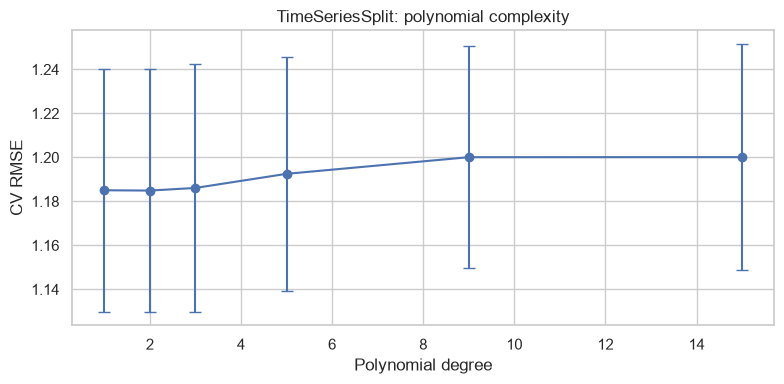

In [15]:
effort_X = model_df[["effort_index"]]
effort_y = model_df["final_cgpa"]
# Keep the same chronological training rows
effort_train = effort_X.iloc[:split_idx]
effort_y_train = effort_y.iloc[:split_idx]

degrees = [1, 2, 3, 5, 9, 15]
tscv = TimeSeriesSplit(n_splits=5)
poly_rows = []
for degree in degrees:
    poly_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lr", LinearRegression())
    ])
    scores = cross_val_score(
        poly_pipe, effort_train, effort_y_train, cv=tscv,
        scoring="neg_root_mean_squared_error"
    )
    poly_rows.append({"Degree": degree, "Mean CV RMSE": -scores.mean(), "Std CV RMSE": scores.std()})
poly_results = pd.DataFrame(poly_rows)
display(poly_results)
plt.figure(figsize=(8, 4))
plt.errorbar(poly_results["Degree"], poly_results["Mean CV RMSE"],
             yerr=poly_results["Std CV RMSE"], marker="o", capsize=4)
plt.xlabel("Polynomial degree"); plt.ylabel("CV RMSE")
plt.title("TimeSeriesSplit: polynomial complexity")
plt.tight_layout(); plt.show()


## Part D – Improving model generalization

### D.1 Handling high-cardinality `cohort_code`

In [16]:
# sklearn TargetEncoder is available in recent sklearn releases (>=1.3).
from sklearn.preprocessing import TargetEncoder

d1 = model_df.copy()
d1_train = d1.iloc[:split_idx].copy()
d1_y = d1_train["final_cgpa"]
d1_base_cols = feature_cols

# Build fold-safe time-series validation manually for the three approaches.
def d1_score(strategy):
    Xd1 = d1_train[d1_base_cols + ["cohort_code"]].copy()
    splitter = TimeSeriesSplit(n_splits=5)
    scores = []
    for tr_idx, val_idx in splitter.split(Xd1):
        Xtr, Xval = Xd1.iloc[tr_idx].copy(), Xd1.iloc[val_idx].copy()
        ytr, yval = d1_y.iloc[tr_idx], d1_y.iloc[val_idx]

        numeric_features = d1_base_cols
        num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])

        if strategy == "remove":
            prep = ColumnTransformer([("num", num_pipe, numeric_features)], remainder="drop")
        elif strategy == "rare_group":
            cat_pipe = Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))
            ])
            prep = ColumnTransformer([
                ("num", num_pipe, numeric_features),
                ("cat", cat_pipe, ["cohort_code"])
            ])
        elif strategy == "target_encode":
            # Fit encoder only on the fold's training partition.
            te = TargetEncoder(cv=5, shuffle=False)
            tr_cat = te.fit_transform(Xtr[["cohort_code"]], ytr)
            val_cat = te.transform(Xval[["cohort_code"]])
            num_imputer = SimpleImputer(strategy="median")
            tr_num = num_imputer.fit_transform(Xtr[numeric_features])
            val_num = num_imputer.transform(Xval[numeric_features])
            model = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)
            model.fit(np.hstack([tr_num, tr_cat]), ytr)
            scores.append(rmse(yval, model.predict(np.hstack([val_num, val_cat]))))
            continue

        model = Pipeline([
            ("prep", prep),
            ("tree", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
        ])
        model.fit(Xtr, ytr)
        scores.append(rmse(yval, model.predict(Xval)))
    return float(np.mean(scores)), float(np.std(scores))

d1_results = []
for strategy, label in [
    ("rare_group", "Rare-category grouping + one-hot"),
    ("target_encode", "Out-of-fold target encoding"),
    ("remove", "Remove cohort_code")
]:
    mean_score, std_score = d1_score(strategy)
    d1_results.append([label, mean_score, std_score])
d1_results = pd.DataFrame(d1_results, columns=["Treatment", "Mean validation RMSE", "Std validation RMSE"])
display(d1_results)


,Treatment,Mean validation RMSE,Std validation RMSE
0,Rare-category grouping + one-hot,1.371862,0.130977
1,Out-of-fold target encoding,1.363964,0.130181
2,Remove cohort_code,1.370475,0.160208


### D.2 Feature selection: with versus without `submission_day`

In [17]:
# Compare models with and without submission_day using the same time-series folds.
base_without_day = [c for c in feature_cols if c != "submission_day"]
model_factories = {
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree depth=5": lambda: DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "Gradient Boosting": lambda: GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
    )
}
def evaluate_day_option(cols, factory):
    scores = []
    for tr, va in TimeSeriesSplit(n_splits=5).split(X_train):
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", factory())
        ])
        pipe.fit(X_train.iloc[tr][cols], y_train.iloc[tr])
        scores.append(rmse(y_train.iloc[va], pipe.predict(X_train.iloc[va][cols])))
    return np.mean(scores)

day_rows = []
for name, factory in model_factories.items():
    for label, cols in [("With submission_day", feature_cols), ("Without submission_day", base_without_day)]:
        day_rows.append([name, label, evaluate_day_option(cols, factory)])
day_results = pd.DataFrame(day_rows, columns=["Model", "Features", "Mean validation RMSE"])
display(day_results.pivot(index="Model", columns="Features", values="Mean validation RMSE"))


Features,With submission_day,Without submission_day
Model,,
Decision Tree depth=5,1.370475,1.310622
Gradient Boosting,1.178994,1.160046
Linear Regression,1.168810,1.162906


### D.3 Regularization on degree-5 polynomial features of `effort_index`

In [18]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
regularized_models = {"Linear Regression": (LinearRegression(), [None]),
                      "Ridge": (Ridge(), alphas),
                      "Lasso": (Lasso(max_iter=100000), alphas)}
reg_rows = []
best_reg = {}
for model_name, (estimator, alpha_values) in regularized_models.items():
    candidates = []
    for alpha in alpha_values:
        model = clone(estimator)
        if alpha is not None:
            model.set_params(alpha=alpha)
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("poly", PolynomialFeatures(degree=5, include_bias=False)),
            ("scaler", StandardScaler()),
            ("model", model)
        ])
        scores = cross_val_score(
            pipe, effort_train, effort_y_train, cv=TimeSeriesSplit(n_splits=5),
            scoring="neg_root_mean_squared_error"
        )
        candidates.append((float(-scores.mean()), alpha, pipe, float(scores.std())))
    best = min(candidates, key=lambda x: x[0])
    best_reg[model_name] = best
    reg_rows.append([model_name, best[1], best[0], best[3]])
reg_results = pd.DataFrame(reg_rows, columns=["Model", "Selected alpha", "Mean CV RMSE", "Std CV RMSE"])
display(reg_results)

# Fit best polynomial models to training data and inspect coefficients.
for model_name, (score, alpha, pipe, std) in best_reg.items():
    pipe.fit(effort_train, effort_y_train)
    estimator = pipe.named_steps["model"]
    coefs = np.asarray(estimator.coef_)
    zeros = int(np.isclose(coefs, 0).sum())
    print(f"{model_name}: coefficients={len(coefs)}, exactly/nearly zero={zeros}, intercept={estimator.intercept_:.4f}")
    print("Coefficients:", np.round(coefs, 4))


,Model,Selected alpha,Mean CV RMSE,Std CV RMSE
0,Linear Regression,NaN,1.192495,0.053353
1,Ridge,10.00,1.185497,0.055796
2,Lasso,0.01,1.184759,0.055062


Linear Regression: coefficients=5, exactly/nearly zero=0, intercept=8.0306
Coefficients: [  1.3164  -5.0872  11.3734 -10.943    3.8046]
Ridge: coefficients=5, exactly/nearly zero=0, intercept=8.0306
Coefficients: [ 0.3723  0.1582  0.0144 -0.0517 -0.0467]
Lasso: coefficients=5, exactly/nearly zero=4, intercept=8.0306
Coefficients: [ 0.4508  0.      0.     -0.     -0.    ]


### D.4 Final model comparison on the untouched chronological test set

In [19]:
# Final feature choice: use D.1's best cohort treatment and D.2's validation result.
# For a common numeric feature matrix, cohort_code is included only if rare grouping wins.
best_cohort = d1_results.loc[d1_results["Mean validation RMSE"].idxmin(), "Treatment"]
use_cohort = best_cohort != "Remove cohort_code"
best_day_row = day_results.groupby("Features")["Mean validation RMSE"].mean()
use_day = best_day_row.get("With submission_day", np.inf) < best_day_row.get("Without submission_day", np.inf)

final_features = base_without_day.copy() if not use_day else feature_cols.copy()
print("Selected cohort treatment:", best_cohort)
print("Keep submission_day:", use_day)
print("Final common features:", final_features)

Xtr_final, Xte_final = X_train[final_features], X_test[final_features]

# Baseline
final_rows = []
baseline = DummyRegressor(strategy="mean").fit(Xtr_final, y_train)
final_rows.append(["Baseline (training mean)", rmse(y_train, baseline.predict(Xtr_final)),
                   rmse(y_test, baseline.predict(Xte_final)), r2_score(y_test, baseline.predict(Xte_final))])

# Linear Regression
lr_final = Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", LinearRegression())])
lr_final.fit(Xtr_final, y_train)
final_rows.append(["Linear Regression", rmse(y_train, lr_final.predict(Xtr_final)),
                   rmse(y_test, lr_final.predict(Xte_final)), r2_score(y_test, lr_final.predict(Xte_final))])

# Ridge/Lasso alpha selected by TimeSeriesSplit on final feature matrix
ridge_candidates = []
for alpha in alphas:
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))])
    scores = cross_val_score(pipe, Xtr_final, y_train, cv=TimeSeriesSplit(n_splits=5),
                             scoring="neg_root_mean_squared_error")
    ridge_candidates.append((-scores.mean(), alpha))
best_alpha = min(ridge_candidates)[1]
ridge_final = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()), ("model", Ridge(alpha=best_alpha))])
ridge_final.fit(Xtr_final, y_train)
final_rows.append([f"Ridge (alpha={best_alpha})", rmse(y_train, ridge_final.predict(Xtr_final)),
                   rmse(y_test, ridge_final.predict(Xte_final)), r2_score(y_test, ridge_final.predict(Xte_final))])

# Decision tree depth selected with chronological CV
tree_candidates = []
for depth in depths:
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("model", DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE))])
    scores = cross_val_score(pipe, Xtr_final, y_train, cv=TimeSeriesSplit(n_splits=5),
                             scoring="neg_root_mean_squared_error")
    tree_candidates.append((-scores.mean(), depth))
best_depth = min(tree_candidates, key=lambda z: z[0])[1]
tree_final = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("model", DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))])
tree_final.fit(Xtr_final, y_train)
final_rows.append([f"Decision Tree (depth={best_depth})", rmse(y_train, tree_final.predict(Xtr_final)),
                   rmse(y_test, tree_final.predict(Xte_final)), r2_score(y_test, tree_final.predict(Xte_final))])

# Gradient boosting: last 15% of training is chronological validation block.
gb_imputer = SimpleImputer(strategy="median")
cut = int(0.85 * len(Xtr_final))
X_gb_fit = gb_imputer.fit_transform(Xtr_final.iloc[:cut])
X_gb_val = gb_imputer.transform(Xtr_final.iloc[cut:])
y_gb_fit, y_gb_val = y_train.iloc[:cut], y_train.iloc[cut:]
gb_search = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
).fit(X_gb_fit, y_gb_fit)
stage_errors = []
for stage_pred in gb_search.staged_predict(X_gb_val):
    stage_errors.append(rmse(y_gb_val, stage_pred))
best_n_estimators = int(np.argmin(stage_errors) + 1)
gb_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(n_estimators=best_n_estimators, learning_rate=0.05,
                                        max_depth=3, random_state=RANDOM_STATE))
]).fit(Xtr_final, y_train)
final_rows.append([f"Gradient Boosting ({best_n_estimators} trees)",
                   rmse(y_train, gb_final.predict(Xtr_final)),
                   rmse(y_test, gb_final.predict(Xte_final)),
                   r2_score(y_test, gb_final.predict(Xte_final))])

final_results = pd.DataFrame(final_rows, columns=["Model", "Training RMSE", "Testing RMSE", "Testing R²"])
display(final_results)


Selected cohort treatment: Out-of-fold target encoding
Keep submission_day: False
Final common features: ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age']


,Model,Training RMSE,Testing RMSE,Testing R²
0,Baseline (training mean),1.268541,1.236164,-0.002862
1,Linear Regression,1.131344,1.099940,0.205987
2,Ridge (alpha=100),1.132331,1.102112,0.202848
3,Decision Tree (depth=2),1.184931,1.145821,0.138365
4,Gradient Boosting (55 trees),1.081140,1.101082,0.204337


## Final discussion

In [20]:
best_model_row = final_results.loc[final_results["Testing RMSE"].idxmin()]
largest_gap_row = (final_results.assign(
    gap=final_results["Testing RMSE"] - final_results["Training RMSE"]
).sort_values("gap", ascending=False).iloc[0])

print("1. Best generalization (lowest test RMSE):", best_model_row["Model"],
      f"(test RMSE={best_model_row['Testing RMSE']:.4f}).")
print("2. Largest generalization gap:", largest_gap_row["Model"],
      f"(gap={largest_gap_row['gap']:.4f}).")
print("3. Effective techniques should be identified from validation/test comparisons above:",
      "complexity control, regularization, leakage-safe preprocessing, and removing weak features.")
print("4. Model selection should use validation performance because training error is optimistic and does not estimate performance on unseen future data.")
print("5. The final test set must remain untouched so it provides an unbiased final estimate after all choices are fixed.")
print("6. A modest R² suggests the survey answers explain only part of CGPA variation; self-reported, grouped and noisy answers leave substantial variation unexplained. A suspiciously high score can indicate leakage rather than genuine generalization.")


1. Best generalization (lowest test RMSE): Linear Regression (test RMSE=1.0999).
2. Largest generalization gap: Gradient Boosting (55 trees) (gap=0.0199).
3. Effective techniques should be identified from validation/test comparisons above: complexity control, regularization, leakage-safe preprocessing, and removing weak features.
4. Model selection should use validation performance because training error is optimistic and does not estimate performance on unseen future data.
5. The final test set must remain untouched so it provides an unbiased final estimate after all choices are fixed.
6. A modest R² suggests the survey answers explain only part of CGPA variation; self-reported, grouped and noisy answers leave substantial variation unexplained. A suspiciously high score can indicate leakage rather than genuine generalization.


## Submission checklist

- [ ] Put `hybrid_student_performance_1200.csv` beside this notebook.
- [ ] Run all cells from top to bottom.
- [ ] Inspect the outputs and adapt the written interpretations to the actual results.
- [ ] Verify that no test-set results were used to choose features or hyperparameters.
- [ ] Submit this single notebook with the generated tables and plots.